# 2.0 - Time-Series EDA & External Variable Merging
**Week 2** | Where and when do delays happen? Which carriers drift? Does weather matter?

Weather is an *external* table (`weather_daily`) merged on **origin city + dispatch date** by `src.dataset.merge_weather` (a pandas `merge`).

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")
clean = pd.read_csv(config.DATA_INTERIM / 'shipments_clean.csv', parse_dates=['dispatch_time','delivery_time'])
weather = F.load_weather()
table = F.build_model_table(clean, weather)
print(table.shape, '| weather join misses:', int(table.precip_mm.isna().sum()))
table[['shipment_id','dispatch_time','origin_city','precip_mm','precip_flag','vendor_roll_delay','route']].head()

(30000, 42) | weather join misses: 0


,shipment_id,dispatch_time,origin_city,precip_mm,precip_flag,vendor_roll_delay,route
0,101603,2024-01-01 00:08:00,Mumbai,0.0,0,NaN,Mumbai -> Mumbai
1,113774,2024-01-01 01:06:00,Kolkata,0.0,0,NaN,Kolkata -> Kolkata
2,101573,2024-01-01 04:15:00,Ahmedabad,0.0,0,NaN,Ahmedabad -> Ahmedabad
3,129083,2024-01-01 05:04:00,Kolkata,0.0,0,NaN,Kolkata -> Kolkata
4,119631,2024-01-01 06:24:00,Mumbai,0.0,0,NaN,Mumbai -> Pune


## 1. Delay by day of week, month and hour

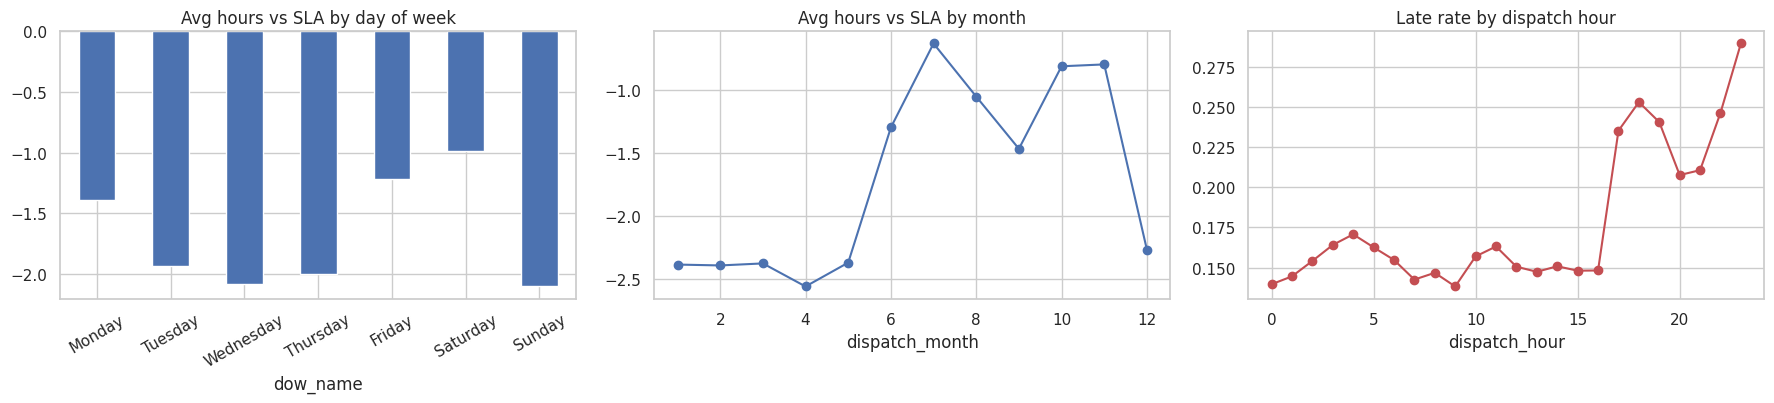

In [2]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
table['dow_name'] = table.dispatch_time.dt.day_name()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
table.groupby('dow_name').hours_delayed.mean().reindex(order).plot.bar(ax=ax[0], color='C0', title='Avg hours vs SLA by day of week')
table.groupby('dispatch_month').hours_delayed.mean().plot(ax=ax[1], marker='o', title='Avg hours vs SLA by month')
table.groupby('dispatch_hour').is_late.mean().plot(ax=ax[2], marker='o', color='C3', title='Late rate by dispatch hour')
ax[0].tick_params(axis='x', rotation=30)
plt.tight_layout(); save('03_delay_by_time.png'); plt.show()

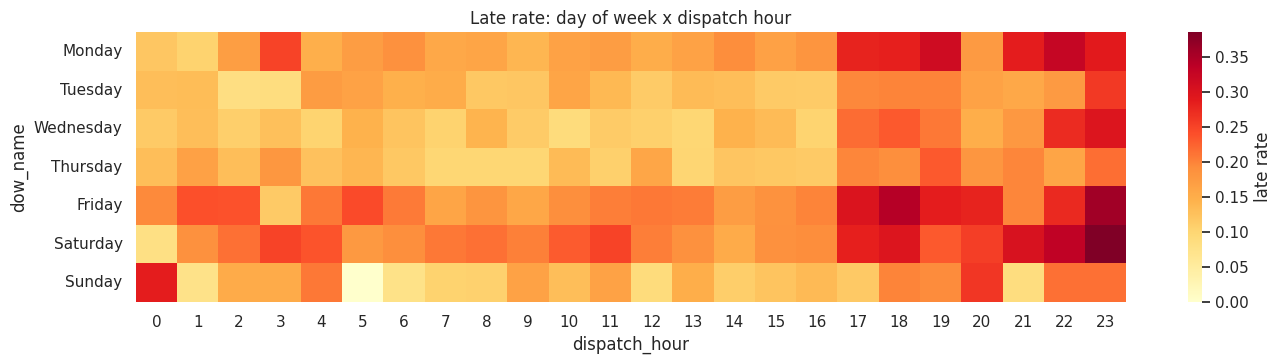

In [3]:
pv = table.pivot_table(index='dow_name', columns='dispatch_hour', values='is_late', aggfunc='mean').reindex(order)
plt.figure(figsize=(14, 3.8)); sns.heatmap(pv, cmap='YlOrRd', cbar_kws={'label': 'late rate'}); plt.title('Late rate: day of week x dispatch hour')
plt.tight_layout(); save('04_heatmap_dow_hour.png'); plt.show()

## 2. Delay by carrier

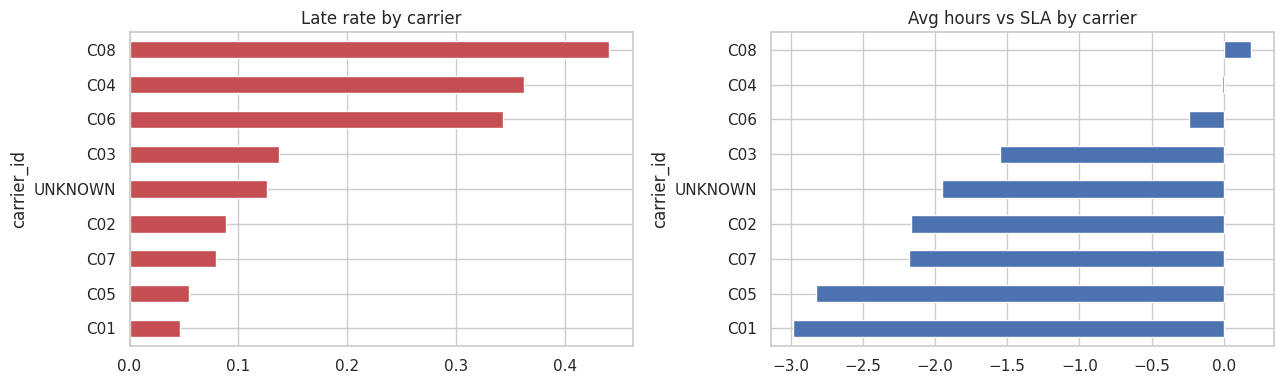

,shipments,avg_delay_h,late_rate
carrier_id,,,
C01,4816,-2.981,0.046
C05,4121,-2.823,0.054
C07,3017,-2.179,0.080
C02,4811,-2.167,0.089
UNKNOWN,150,-1.950,0.127
C03,3863,-1.548,0.137
C06,3011,-0.239,0.343
C04,3839,-0.009,0.363
C08,2372,0.189,0.441


In [4]:
car = table.groupby('carrier_id').agg(shipments=('shipment_id','size'), avg_delay_h=('hours_delayed','mean'), late_rate=('is_late','mean')).sort_values('late_rate')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
car.late_rate.plot.barh(ax=ax[0], color='C3', title='Late rate by carrier'); car.avg_delay_h.plot.barh(ax=ax[1], color='C0', title='Avg hours vs SLA by carrier')
plt.tight_layout(); save('05_delay_by_carrier.png'); plt.show(); car.round(3)

## 3. Rolling averages for vendor performance
Daily carrier KPIs with **7-day and 30-day rolling means**. Drift in these curves is why vendor-history features are valuable.

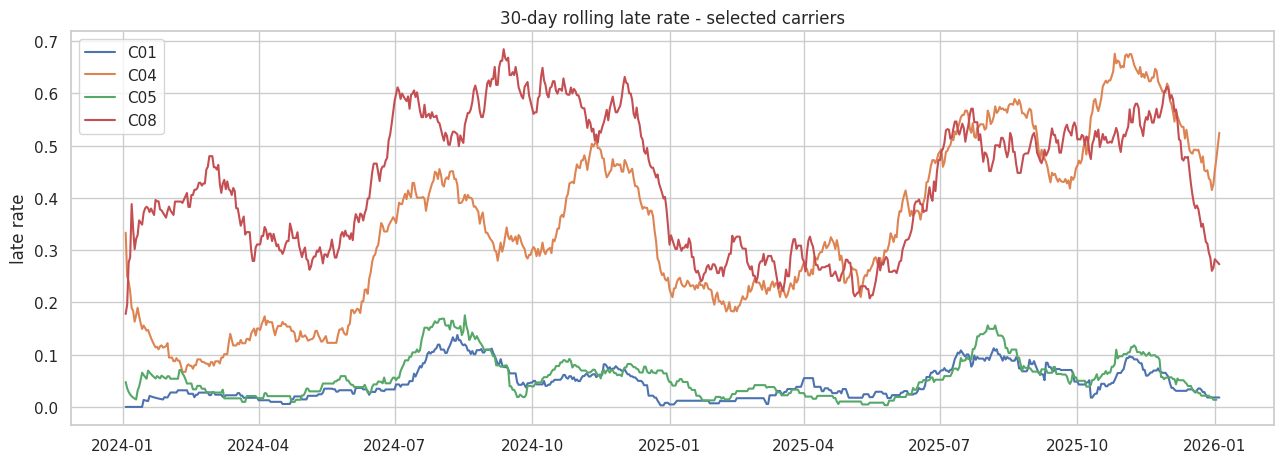

In [5]:
cp = F.carrier_daily_performance(table)
fig, ax = plt.subplots(figsize=(13, 4.8))
for cid, g in cp.groupby('carrier_id'):
    if cid in ('C04','C05','C08','C01'): ax.plot(g.delivery_date, g.roll30d_late_rate, label=cid)
ax.set_title('30-day rolling late rate - selected carriers'); ax.set_ylabel('late rate'); ax.legend()
plt.tight_layout(); save('06_vendor_rolling.png'); plt.show()

## 4. Weather effect
Weather columns come from the merge in `src/dataset.py`.

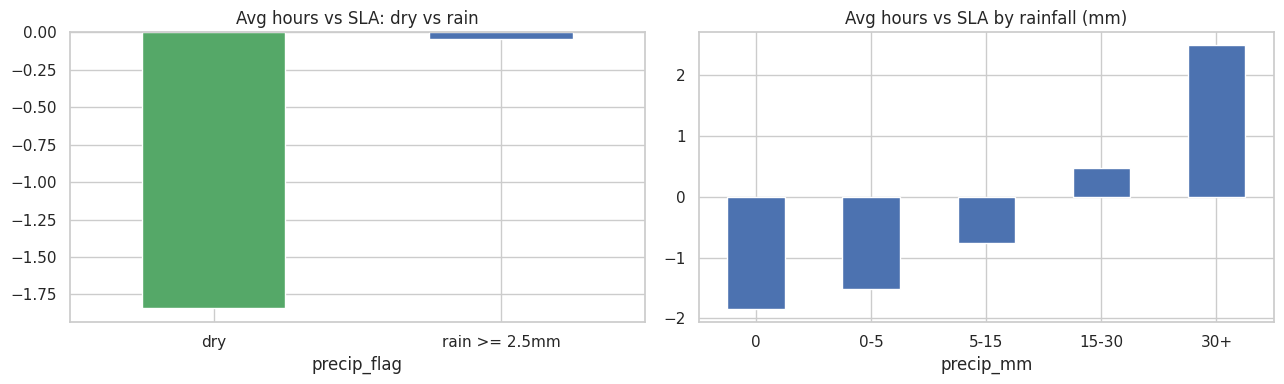

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
table.groupby('precip_flag').hours_delayed.mean().rename({0:'dry',1:'rain >= 2.5mm'}).plot.bar(ax=ax[0], color=['C2','C0'], title='Avg hours vs SLA: dry vs rain'); ax[0].tick_params(axis='x', rotation=0)
bins = pd.cut(table.precip_mm, [-.1, 0, 5, 15, 30, 200], labels=['0','0-5','5-15','15-30','30+'])
table.groupby(bins).hours_delayed.mean().plot.bar(ax=ax[1], title='Avg hours vs SLA by rainfall (mm)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); save('07_weather_effect.png'); plt.show()

In [7]:
route = table.groupby('route').agg(n=('shipment_id','size'), late_rate=('is_late','mean'), avg_delay=('hours_delayed','mean')).query('n >= 100').sort_values('late_rate', ascending=False)
route.head(10).round(3)

,n,late_rate,avg_delay
route,,,
Mumbai -> Hyderabad,109,0.358,-1.105
Kolkata -> Lucknow,110,0.282,-1.735
Mumbai -> Nagpur,107,0.280,-1.704
Hyderabad -> Mumbai,135,0.274,-1.296
Pune -> Surat,228,0.272,-0.821
Hyderabad -> Nashik,126,0.262,-1.752
Hyderabad -> Coimbatore,104,0.260,-1.885
Pune -> Nagpur,117,0.256,-1.591
Mumbai -> Indore,118,0.254,-1.323


In [8]:
table.to_csv(config.DATA_PROCESSED / 'shipments_enriched.csv', index=False)
cp.to_csv(config.DATA_PROCESSED / 'carrier_daily_performance.csv', index=False)
print('saved', table.shape)

saved (30000, 43)


## Findings
* **Seasonality:** monsoon months and the Oct-Nov festive peak add delay.
* **Day / hour:** Monday, Friday and weekend dispatches and evening/night dispatches are late more often.
* **Carriers differ and drift** - a rolling vendor-performance feature is justified.
* **Rain** raises delay, with larger effect at heavy rainfall.

**Next:** regression modelling (3.0).